# PBL JS09 - Klasifikasi kNN dan Naive Bayes

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js09-klasifikasi)

Notebook ini menerapkan langkah-langkah jobsheet JS09 pada **dataset PBL: Malicious URL Detection**
(`Malicious URL Detection.csv` di root repositori). Dataset berisi 783.705 URL dengan kolom `url` dan `type`, terbagi ke 7 kelas:
`benign`, `legitimate`, `defacement`, `phishing`, `malware`, `spam`, dan `Exploit`.
URL sudah dinormalisasi oleh sumbernya (huruf kecil, tanpa `http(s)://` dan `www.`).
Fungsi muat data dan ekstraksi fitur leksikal ada di modul bersama [`pbl_url.py`](../pbl_url.py), sehingga semua notebook PBL memakai definisi fitur yang sama.

**Pemetaan langkah jobsheet → dataset PBL:**


| Jobsheet JS09 | Penerapan pada URL |
| --- | --- |
| Praktikum 1 - kNN: eksplorasi, preprocessing, model, evaluasi | kNN pada 28 fitur leksikal terstandardisasi |
| Tugas 1 - pengaruh jumlah fitur dan nilai k | Variasi k dan jumlah fitur (urutan mutual information) |
| Praktikum 2 - Gaussian vs Multinomial Naive Bayes | GaussianNB pada fitur numerik |
| Praktikum 3 & Tugas 2 - MultinomialNB, CountVectorizer vs TF-IDF | URL sebagai teks: token dan n-gram karakter |

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pbl_url
np.random.seed(42)
print('Kernel:', sys.executable)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python


## Langkah 1-4 - Load data, eksplorasi singkat, preprocessing

In [2]:
df = pbl_url.load_urls()
print(df.shape)
df.head()

(783705, 2)


,url,type
0,mp3raid.com/music/krizz_kaliko.html,benign
1,bopsecrets.org/rexroth/cr/1.htm,benign
2,buzzfil.net/m/show-art/ils-etaient-loin-de-s-i...,benign
3,espn.go.com/nba/player/_/id/3457/brandon-rush,benign
4,yourbittorrent.com/?q=anthony-hamilton-soulife,benign


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
X = pbl_url.lexical_features(df['url']); y = df['type'].to_numpy()
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=42)
print('train', len(idx_tr), '| test', len(idx_te))
# kNN menyimpan seluruh data latih dan menghitung jarak ke semuanya, sehingga dipakai subset stratified
knn_tr, _ = train_test_split(idx_tr, train_size=150000, stratify=y[idx_tr], random_state=0)
knn_te, _ = train_test_split(idx_te, train_size=30000, stratify=y[idx_te], random_state=0)
scaler = StandardScaler().fit(X.iloc[knn_tr])
Xtr, Xte = scaler.transform(X.iloc[knn_tr]), scaler.transform(X.iloc[knn_te]); ytr, yte = y[knn_tr], y[knn_te]

train 626964 | test 156741


## Langkah 5-6 - Model kNN dan evaluasi

kNN k=5: 1.6 s, accuracy=0.7990, macro-F1=0.6670
              precision    recall  f1-score   support

     Exploit     0.7778    0.7778    0.7778         9
      benign     0.8199    0.8611    0.8400     16324
  defacement     0.8273    0.8275    0.8274      3647
  legitimate     0.2295    0.1261    0.1628       222
     malware     0.8933    0.8527    0.8725       903
    phishing     0.7415    0.6887    0.7142      8790
        spam     0.7255    0.3524    0.4744       105

    accuracy                         0.7990     30000
   macro avg     0.7164    0.6409    0.6670     30000
weighted avg     0.7954    0.7990    0.7963     30000



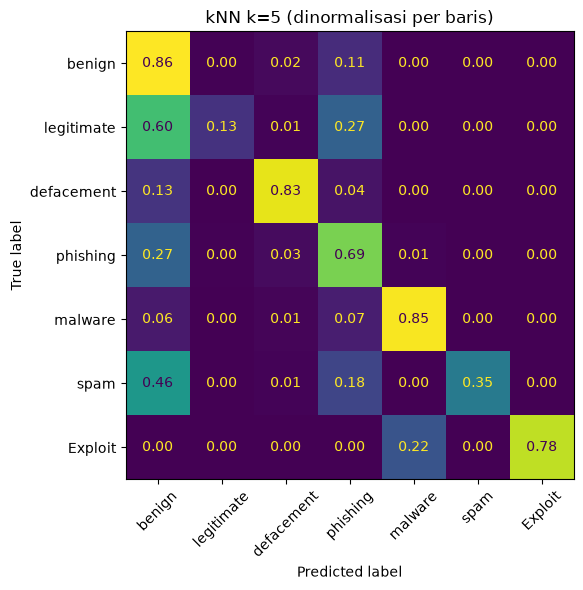

In [4]:
from sklearn.neighbors import KNeighborsClassifier
t0 = time.perf_counter(); knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1).fit(Xtr, ytr); pred = knn.predict(Xte)
print(f'kNN k=5: {time.perf_counter() - t0:.1f} s, accuracy={accuracy_score(yte, pred):.4f}, macro-F1={f1_score(yte, pred, average="macro"):.4f}')
print(classification_report(yte, pred, digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(yte, pred, labels=pbl_url.CLASSES, normalize='true', values_format='.2f', ax=ax, colorbar=False, xticks_rotation=45)
plt.title('kNN k=5 (dinormalisasi per baris)'); plt.tight_layout(); plt.show()

## Tugas 1 - Pengaruh nilai k dan jumlah fitur

In [5]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import StratifiedKFold, cross_val_score

n_fitur,5,10,20,28
k,,,,
1,0.4734,0.5102,0.5896,0.5955
3,0.4840,0.5215,0.5967,0.6336
5,0.4685,0.5210,0.5989,0.6258
11,0.4765,0.5080,0.5787,0.6214
25,0.3895,0.4212,0.4865,0.5337


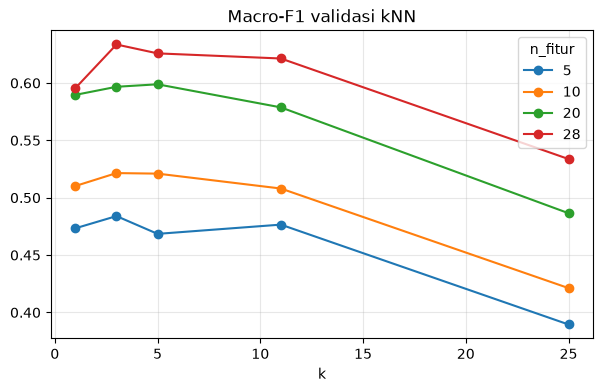

Terbaik di validasi: {'n_fitur': 28.0, 'k': 3.0, 'val_accuracy': 0.7979, 'val_macro_F1': 0.6335593652828793}


In [6]:
mi = pd.Series(mutual_info_classif(Xtr[:40000], ytr[:40000], random_state=42), index=X.columns).sort_values(ascending=False)
val_tr, val_va = train_test_split(np.arange(len(Xtr)), test_size=0.2, stratify=ytr, random_state=1)   # validasi dari data latih
rows = []
for n_feat in [5, 10, 20, 28]:
    cols = [X.columns.get_loc(c) for c in mi.index[:n_feat]]
    for k in [1, 3, 5, 11, 25]:
        m = KNeighborsClassifier(n_neighbors=k, n_jobs=-1).fit(Xtr[val_tr][:, cols], ytr[val_tr])
        p_ = m.predict(Xtr[val_va][:, cols])
        rows.append({'n_fitur': n_feat, 'k': k, 'val_accuracy': accuracy_score(ytr[val_va], p_), 'val_macro_F1': f1_score(ytr[val_va], p_, average='macro')})
grid = pd.DataFrame(rows)
display(grid.pivot(index='k', columns='n_fitur', values='val_macro_F1').round(4))
grid.pivot(index='k', columns='n_fitur', values='val_macro_F1').plot(marker='o', figsize=(7, 4), title='Macro-F1 validasi kNN'); plt.grid(alpha=.3); plt.show()
best = grid.sort_values('val_macro_F1', ascending=False).iloc[0]; print('Terbaik di validasi:', best.to_dict())

## Praktikum 2 - Gaussian Naive Bayes pada fitur numerik

In [7]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB
Xall_tr, Xall_te = X.iloc[idx_tr], X.iloc[idx_te]
gnb = GaussianNB().fit(Xall_tr, y[idx_tr]); p_g = gnb.predict(Xall_te)
gnb_log = GaussianNB().fit(np.log1p(Xall_tr.clip(lower=0)), y[idx_tr]); p_gl = gnb_log.predict(np.log1p(Xall_te.clip(lower=0)))
print(f'GaussianNB fitur mentah : acc={accuracy_score(y[idx_te], p_g):.4f}, macro-F1={f1_score(y[idx_te], p_g, average="macro"):.4f}')
print(f'GaussianNB fitur log1p  : acc={accuracy_score(y[idx_te], p_gl):.4f}, macro-F1={f1_score(y[idx_te], p_gl, average="macro"):.4f}')

GaussianNB fitur mentah : acc=0.1872, macro-F1=0.1732
GaussianNB fitur log1p  : acc=0.1672, macro-F1=0.1535


## Praktikum 3 dan Tugas 2 - Multinomial Naive Bayes: CountVectorizer vs TF-IDF

In [8]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
url_tr, url_te, ytr_all, yte_all = df['url'].iloc[idx_tr], df['url'].iloc[idx_te], y[idx_tr], y[idx_te]
configs = {
    'Count, token kata': CountVectorizer(token_pattern=r'[a-z0-9]+', min_df=2),
    'TF-IDF, token kata': TfidfVectorizer(token_pattern=r'[a-z0-9]+', min_df=2),
    'Count, n-gram karakter 3-5': CountVectorizer(analyzer='char', ngram_range=(3, 5), min_df=3, max_features=300000),
    'TF-IDF, n-gram karakter 3-5': TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=3, max_features=300000, sublinear_tf=True),
}
rows, preds = [], {}
for name, vec in configs.items():
    Xt, Xv = vec.fit_transform(url_tr), vec.transform(url_te)
    for model_name, model in [('MultinomialNB', MultinomialNB(alpha=0.1)), ('ComplementNB', ComplementNB(alpha=0.1))]:
        t0 = time.perf_counter(); p_ = model.fit(Xt, ytr_all).predict(Xv); dur = time.perf_counter() - t0
        preds[(name, model_name)] = p_
        rows.append({'representasi': name, 'model': model_name, 'dimensi': Xt.shape[1], 'accuracy': accuracy_score(yte_all, p_),
                     'macro_F1': f1_score(yte_all, p_, average='macro'), 'waktu_fit_predict_s': dur})
nb_tbl = pd.DataFrame(rows); nb_tbl.round(4)

,representasi,model,dimensi,accuracy,macro_F1,waktu_fit_predict_s
0,"Count, token kata",MultinomialNB,144380,0.8867,0.7292,0.7859
1,"Count, token kata",ComplementNB,144380,0.8853,0.6841,0.7872
2,"TF-IDF, token kata",MultinomialNB,144380,0.8969,0.6208,0.7795
3,"TF-IDF, token kata",ComplementNB,144380,0.8829,0.6928,0.7875
4,"Count, n-gram karakter 3-5",MultinomialNB,300000,0.8247,0.6624,1.5603
5,"Count, n-gram karakter 3-5",ComplementNB,300000,0.8677,0.6659,1.5850
6,"TF-IDF, n-gram karakter 3-5",MultinomialNB,300000,0.8872,0.7078,1.1054
7,"TF-IDF, n-gram karakter 3-5",ComplementNB,300000,0.8825,0.6863,1.1423


In [9]:
best_key = max(preds, key=lambda k: f1_score(yte_all, preds[k], average='macro'))
print('Naive Bayes terbaik:', best_key)
print(classification_report(yte_all, preds[best_key], digits=4, zero_division=0))
summary = pd.DataFrame([
    {'model': f'kNN k=5 (28 fitur, 150k latih)', 'accuracy': accuracy_score(yte, pred), 'macro_F1': f1_score(yte, pred, average='macro')},
    {'model': 'GaussianNB (28 fitur log1p)', 'accuracy': accuracy_score(y[idx_te], p_gl), 'macro_F1': f1_score(y[idx_te], p_gl, average='macro')},
    {'model': f'{best_key[1]} ({best_key[0]})', 'accuracy': accuracy_score(yte_all, preds[best_key]), 'macro_F1': f1_score(yte_all, preds[best_key], average='macro')},
]).set_index('model'); summary.round(4)

Naive Bayes terbaik: ('Count, token kata', 'MultinomialNB')
              precision    recall  f1-score   support

     Exploit     1.0000    0.4694    0.6389        49
      benign     0.8956    0.9255    0.9103     85286
  defacement     0.9292    0.9791    0.9535     19053
  legitimate     0.2114    0.0637    0.0979      1162
     malware     0.8206    0.8932    0.8554      4718
    phishing     0.8617    0.7985    0.8289     45923
        spam     0.8963    0.7545    0.8193       550

    accuracy                         0.8867    156741
   macro avg     0.8021    0.6977    0.7292    156741
weighted avg     0.8824    0.8867    0.8836    156741



,accuracy,macro_F1
model,,
"kNN k=5 (28 fitur, 150k latih)",0.7990,0.6670
GaussianNB (28 fitur log1p),0.1672,0.1535
"MultinomialNB (Count, token kata)",0.8867,0.7292


## Analisis

| Model | Data latih | Accuracy | Macro-F1 |
| --- | --- | --- | --- |
| kNN k=5 (28 fitur leksikal terstandardisasi) | 150 ribu | 0,799 | 0,667 |
| GaussianNB (28 fitur log1p) | 627 ribu | 0,167 | 0,154 |
| **MultinomialNB (CountVectorizer token kata)** | 627 ribu | **0,887** | **0,729** |

**kNN.** Hasil validasi Tugas 1 menunjukkan bahwa macro-F1 naik seiring jumlah fitur (5 fitur: 0,47-0,48 → 28 fitur: 0,59-0,63). Nilai terbaik ada pada **k=3** (0,634), dan nilai k yang besar (25) menurunkan macro-F1 ke 0,534. k besar menguntungkan kelas mayoritas karena voting di lingkungan yang luas didominasi benign, sehingga kelas langka seperti spam dan Exploit "tertelan" (Cover & Hart, 1967). Recall `spam` hanya 0,35 dan `legitimate` 0,13. Domain legitimate (mis. `rediff.com`) secara leksikal identik dengan domain benign, dan bedanya kemungkinan hanya sumber data (lihat PBL JS02).

**GaussianNB gagal** (accuracy 0,17), bahkan jauh di bawah menebak `benign` terus (0,54). Fitur leksikal adalah hitungan diskret dan indikator biner yang sangat menceng, saling berkorelasi kuat (mis. `digit_ratio`-`letter_ratio` -0,95), dan memiliki varians hampir nol pada kelas kecil (Exploit: `is_ip` = 1 hampir selalu). Asumsi distribusi normal dan independensi bersyarat GaussianNB dilanggar sangat parah. Varians kecil pada kelas langka membuat likelihood Gaussian untuk kelas tersebut sangat runcing, sehingga banyak URL terdorong ke kelas yang salah. Pengecekan tambahan pada sampel stratified 200 ribu URL (test 40 ribu) menunjukkan bahwa GaussianNB memprediksi 38,4% URL sebagai `spam` dan 25,6% sebagai `legitimate`, padahal kedua kelas itu hanya 1,1% dari data. Transformasi `log1p` tidak membantu.

**MultinomialNB pada teks URL (Tugas 2).**
* Representasi terbaik adalah **CountVectorizer token kata** dengan macro-F1 0,729. TF-IDF token memberi accuracy sedikit lebih tinggi (0,897), tetapi macro-F1 turun ke 0,621. Ini sesuai dengan McCallum & Nigam (1998): model *event* multinomial dirancang untuk **jumlah** kata, sehingga pembobotan TF-IDF mengubah statistik yang diasumsikan model.
* **ComplementNB** (Rennie dkk., 2003) dirancang untuk data tidak seimbang, dan membantu pada TF-IDF token (0,621 → 0,693), tetapi tidak pada count token.
* N-gram karakter tidak sebaik pada model linier (PBL JS03), karena n-gram yang tumpang tindih sangat melanggar asumsi independensi Naive Bayes.
* Per kelas, MultinomialNB sangat baik untuk defacement (F1 0,954) dan benign (0,910), cukup baik untuk malware (0,855), phishing (0,829), dan spam (0,819), tetapi gagal untuk legitimate (0,098). Precision Exploit 1,00 dengan recall 0,47.
* Naive Bayes dilatih dan memprediksi 157 ribu URL dalam < 1 detik, jauh lebih cepat daripada kNN yang harus menghitung jarak ke semua data latih.

**Kesimpulan:** untuk URL, Naive Bayes multinomial pada token adalah baseline yang cepat dan kuat. kNN pada fitur leksikal kalah karena fitur tersebut tidak menangkap isi token (nama merek, kata `login`), dan GaussianNB tidak cocok untuk fitur diskret yang menceng.

## Rujukan

1. Cover, T., & Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, 13(1), 21-27. https://doi.org/10.1109/TIT.1967.1053964
2. McCallum, A., & Nigam, K. (1998). A comparison of event models for naive Bayes text classification. *AAAI-98 Workshop on Learning for Text Categorization*, 41-48.
3. Rennie, J. D. M., Shih, L., Teevan, J., & Karger, D. R. (2003). Tackling the poor assumptions of naive Bayes text classifiers. *Proceedings of the 20th International Conference on Machine Learning (ICML)*, 616-623.
4. Ma, J., Saul, L. K., Savage, S., & Voelker, G. M. (2009). Beyond blacklists: Learning to detect malicious web sites from suspicious URLs. *Proceedings of the 15th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 1245-1254. https://doi.org/10.1145/1557019.1557153
5. Mamun, M. S. I., Rathore, M. A., Lashkari, A. H., Stakhanova, N., & Ghorbani, A. A. (2016). Detecting malicious URLs using lexical analysis. *Network and System Security (NSS 2016)*, LNCS 9955, 467-482. https://doi.org/10.1007/978-3-319-46298-1_30
6. He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering*, 21(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239
7. Sokolova, M., & Lapalme, G. (2009). A systematic analysis of performance measures for classification tasks. *Information Processing & Management*, 45(4), 427-437. https://doi.org/10.1016/j.ipm.2009.03.002